# Tagesmitteltemperatur im Jahresvergleich

Das Diagramm legt die täglichen DWD-Mitteltemperaturen für Berlin-Dahlem jahresweise übereinander. Die x-Achse zeigt den Jahresverlauf von Januar bis Dezember; fehlende Messwerte bleiben als Lücken sichtbar. 2026 ist nur bis zum letzten vorhandenen DWD-Tag enthalten.

## Daten laden und Kalenderverlauf vorbereiten

Der 29. Februar wird im Kalendervergleich beibehalten; dadurch können Nicht-Schaltjahre an diesem Tag eine kleine Linienlücke haben.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

csv_datei = Path("DWD_Berlin_Dahlem_Tagesdaten_2020_heute.csv")
wetter = pd.read_csv(csv_datei, parse_dates=["datum"])
wetter["jahr"] = wetter["datum"].dt.year
wetter["kalendertag"] = pd.to_datetime("2000-" + wetter["datum"].dt.strftime("%m-%d"))
temperatur_nach_jahr = wetter.pivot_table(
    index="kalendertag",
    columns="jahr",
    values="temp_durch_c",
    aggfunc="mean",
)

print(f"Zeitraum: {wetter['datum'].min():%d.%m.%Y} bis {wetter['datum'].max():%d.%m.%Y}")
print("Jahre im Vergleich:", ", ".join(map(str, temperatur_nach_jahr.columns)))

Zeitraum: 01.01.2020 bis 01.11.2026
Jahre im Vergleich: 2020, 2021, 2022, 2023, 2024, 2025, 2026


## Linien nach Jahr

Jedes Jahr erhält eine eigene Farbe. Die Darstellung verwendet die Tagesmitteltemperatur in °C.

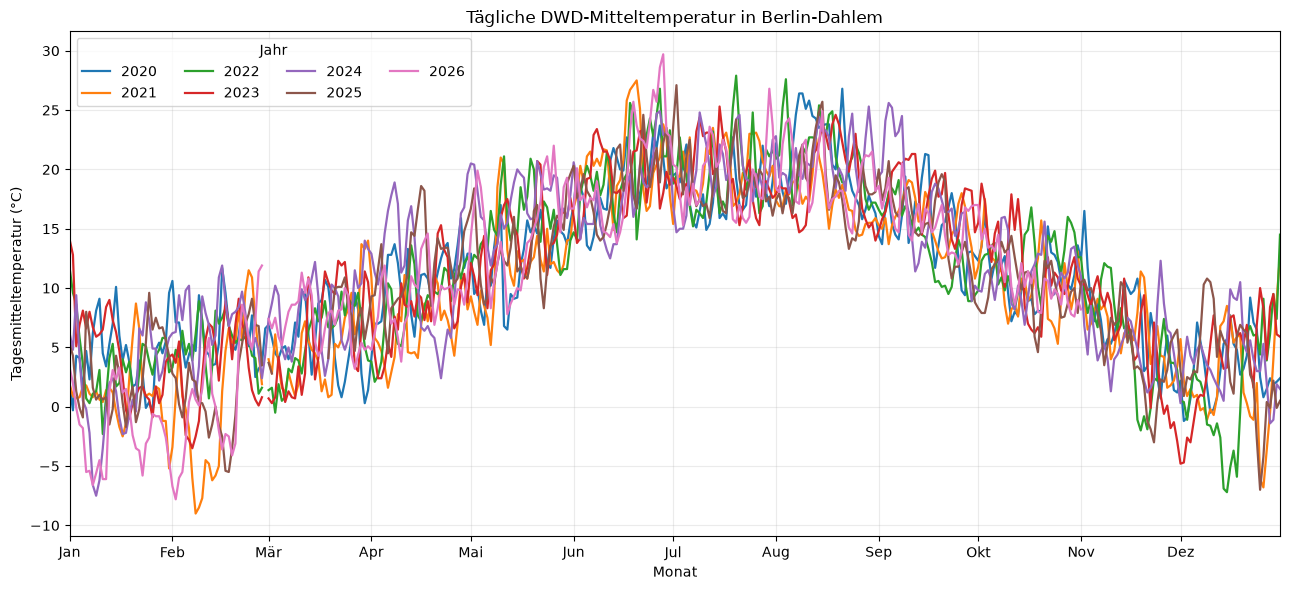

In [2]:
fig, ax = plt.subplots(figsize=(13, 6))

for jahr in temperatur_nach_jahr.columns:
    ax.plot(
        temperatur_nach_jahr.index,
        temperatur_nach_jahr[jahr],
        label=str(jahr),
        linewidth=1.6,
    )

monatsanfang = pd.to_datetime([f"2000-{monat:02d}-01" for monat in range(1, 13)])
ax.set_xticks(monatsanfang)
ax.set_xticklabels(["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"])
ax.set_xlim(pd.Timestamp("2000-01-01"), pd.Timestamp("2000-12-31"))
ax.set_title("Tägliche DWD-Mitteltemperatur in Berlin-Dahlem")
ax.set_xlabel("Monat")
ax.set_ylabel("Tagesmitteltemperatur (°C)")
ax.grid(True, alpha=0.25)
ax.legend(title="Jahr", ncol=4)
fig.tight_layout()
plt.show()